---
title: "Forecast Day-ahead Power Prices with TabPFN-TS"
description: "Forecast tomorrow's 24 hourly EPEX-DE prices with TabPFN-TS through the API, and compare with Chronos-2"
icon: "bolt"
cookbookTags:
  - time-series
  - api
authors:
  - name: Paul Egorov
    linkedin: https://www.linkedin.com/in/paul-egorov/
---

*Tomorrow's 24 hourly power prices from the raw price series: no GPU, no training, no feature engineering.*

Power traders bid today for every hour of tomorrow. When they bid, they know the prices up to today and the published forecasts of load and of wind and solar output for tomorrow.

This notebook forecasts German day-ahead prices with [**TabPFN-TS**](https://docs.priorlabs.ai/capabilities/forecasting) through the Prior Labs API, and compares it with **Chronos-2**, a leading forecasting model, on identical inputs.

- **Data:** hourly EPEX-DE prices and forecasts, 2012–2017.
- **Test:** 84 days across 2017, each forecast using only what was known the day before.
- **Result:** TabPFN-TS has the lower error, most clearly when wind and solar output is high.

## Setup

TabPFN-TS runs on the Prior Labs API, so the notebook needs an API key. To run it:

1. Create a key at [platform.priorlabs.ai/account/api-keys](https://platform.priorlabs.ai/account/api-keys).
2. In Colab, click the key icon in the left sidebar, add a secret named `TABPFN_TOKEN` with your key, and switch on notebook access. Outside Colab, set the `TABPFN_TOKEN` environment variable. If neither is set, the notebook asks for the key; the input is hidden.
3. Run all cells. The install step may print a pip warning about `requests`; it can be ignored.

In [1]:
%pip install -q "tabpfn-time-series==1.4.0" "chronos-forecasting==2.3.2"

In [2]:
import os
import time
import warnings
from getpass import getpass

os.environ["TQDM_DISABLE"] = "1"  # the library's bars reach 100% before the API has answered
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tabpfn_client
import torch
from chronos import Chronos2Pipeline
from tabpfn_time_series import TabPFNMode, TabPFNTSPipeline, TimeSeriesDataFrame

%config InlineBackend.figure_format = "retina"
warnings.simplefilter("ignore")
plt.style.use("seaborn-v0_8-whitegrid")
COLORS = {"TabPFN-TS": "#4E79A7", "Chronos-2": "#8C8C8C", "Actual": "#222222"}

try:
    from google.colab import userdata
    token = userdata.get("TABPFN_TOKEN")
except Exception:  # not in Colab, or no secret with that name
    token = os.environ.get("TABPFN_TOKEN") or getpass("TabPFN API key: ")
tabpfn_client.set_access_token(token.strip())
_ = tabpfn_client.get_api_usage()  # fails here if the key is wrong
os.environ["TABPFN_TOKEN"] = token.strip()  # the pipeline's worker processes read the key from here

## Data

Hourly EPEX-DE day-ahead prices (EUR/MWh) for 2012–2017, with the day-ahead Amprion load forecast and the wind+solar forecast. The file is the [open-access benchmark dataset](https://zenodo.org/records/4624805) of Lago et al. (2021), published with their [epftoolbox](https://github.com/jeslago/epftoolbox). The test set is 12 weeks of 2017, one every four weeks from 16 January, so every season is in it, including the windy week of 23–29 October.

52,416 hours from 2012-01-09 to 2017-12-31; test: 84 days


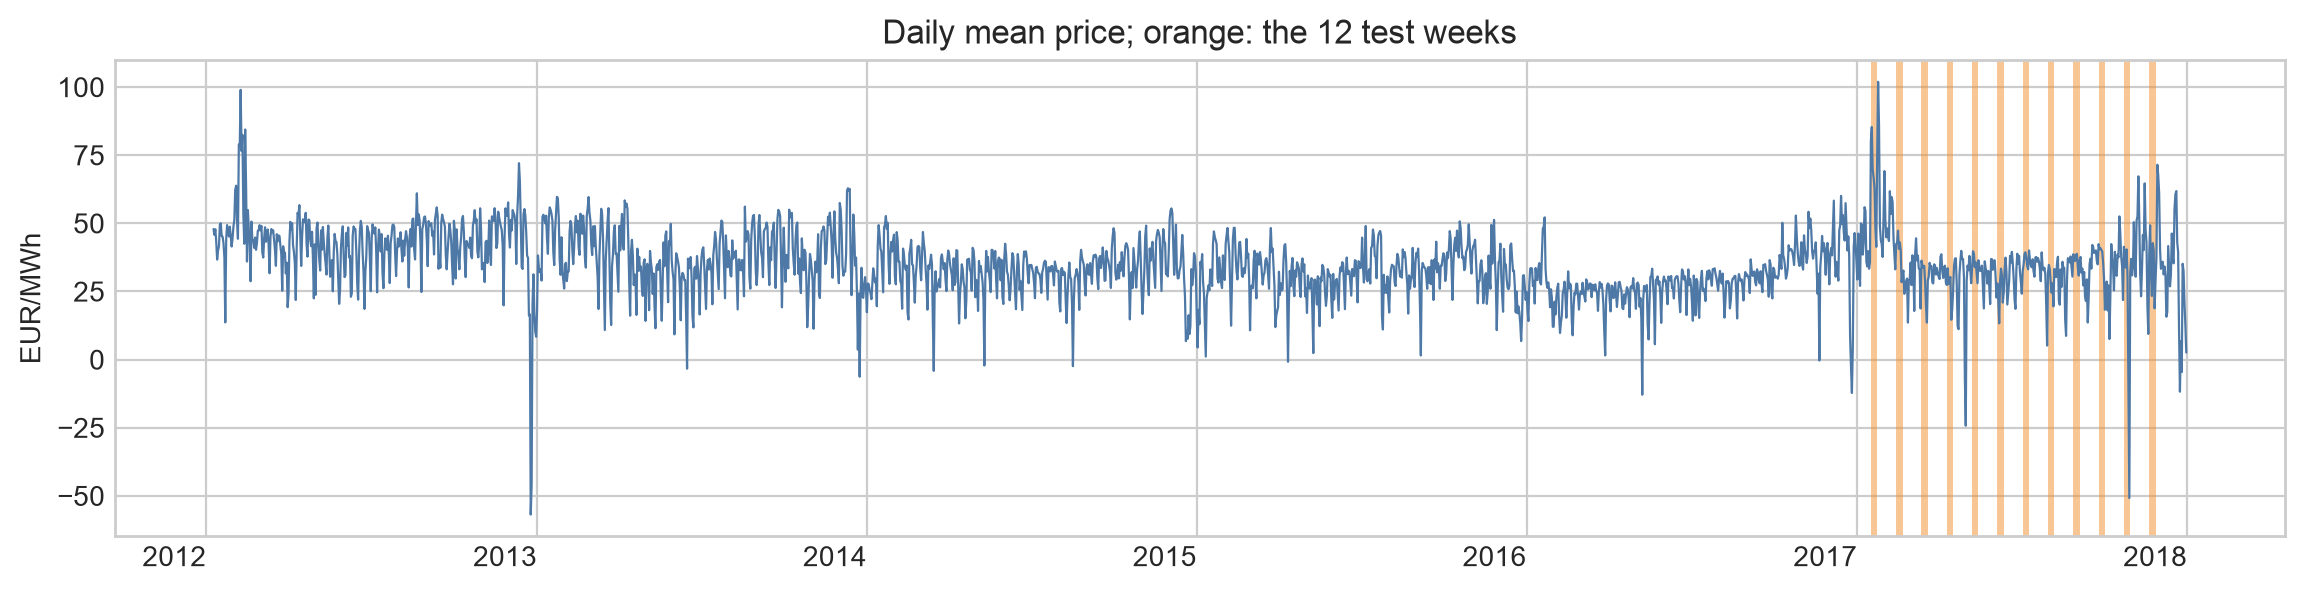

In [3]:
data = pd.read_csv("https://zenodo.org/records/4624805/files/DE.csv?download=1", index_col=0, parse_dates=True)
data.index.name = "timestamp"
data.columns = ["price", "load_forecast", "renewables_forecast"]
COVARIATES = ["load_forecast", "renewables_forecast"]

HOUR = pd.Timedelta(hours=1)
TEST_WEEKS = pd.date_range("2017-01-16", periods=12, freq="28D")
TEST_DAYS = pd.DatetimeIndex([week + pd.Timedelta(days=i) for week in TEST_WEEKS for i in range(7)])
actual = data.loc[data.index.normalize().isin(TEST_DAYS), "price"]
print(f"{len(data):,} hours from {data.index[0]:%Y-%m-%d} to {data.index[-1]:%Y-%m-%d}; test: {len(TEST_DAYS)} days")

ax = data["price"].resample("D").mean().plot(figsize=(14, 3.5), color=COLORS["TabPFN-TS"], linewidth=0.8, x_compat=True, rot=0)
for start in TEST_WEEKS:
    ax.axvspan(start, start + 7 * 24 * HOUR, color="#F28E2B", alpha=0.5, linewidth=0)
ax.set(title="Daily mean price; orange: the 12 test weeks", xlabel="", ylabel="EUR/MWh")
plt.show()

### How the backtest works

We replay 84 trading days. For each delivery day, both models see only what a trader knows at the auction the day before, and nothing is trained: each forecast reads the history directly.

![How the backtest works: for each delivery day, the models see prices up to 23:00 the day before and the load and wind+solar forecasts for the delivery day](https://raw.githubusercontent.com/PriorLabs/tabpfn-cookbook/main/visuals/forecast_day_ahead_power_prices/backtest.png)

No features are built by hand; TabPFN-TS creates its own (see the [tabpfn-time-series](https://github.com/PriorLabs/tabpfn-time-series) repo).

In [4]:
CONTEXT_HOURS = 8192
QUANTILES = [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9]


def window(day):
    """History up to 23:00 the day before `day`, and the covariates for the 24 hours of `day`."""
    history = data.loc[day - CONTEXT_HOURS * HOUR : day - HOUR]
    future = data.loc[day : day + 23 * HOUR, COVARIATES]
    assert len(history) == CONTEXT_HOURS and len(future) == 24
    return history, future


def forecast_test_weeks(forecast):
    """Run `forecast` on each test week, printing the number of weeks done."""
    weeks = []
    for number, week in enumerate(TEST_WEEKS, start=1):
        weeks.append(forecast(pd.date_range(week, periods=7)))
        print(f"{number}/{len(TEST_WEEKS)}", end=" ", flush=True)
    return pd.concat(weeks)

## Forecast

Both models return nine quantiles (10% to 90%) for each of the 24 delivery hours; the median is the point forecast.

### TabPFN-TS

One API fit per delivery day, 84 in total, sent a week at a time. This takes a few minutes, depending on API load; the API allows 60 fits per minute, so the function waits and retries when it hits the limit.

In [5]:
tabpfn_ts = TabPFNTSPipeline(tabpfn_mode=TabPFNMode.CLIENT, max_context_length=CONTEXT_HOURS)


def to_tsdf(frames):
    return TimeSeriesDataFrame.from_data_frame(pd.concat(frames).reset_index())


def forecast_tabpfn_ts(days):
    """Quantile forecasts for the 24 hours of each day in `days`, through the API."""
    context, future = [], []
    for day in days:  # build the inputs: one item per delivery day
        history, covariates = window(day)
        item = str(day.date())
        context.append(history.rename(columns={"price": "target"}).assign(item_id=item))
        future.append(covariates.assign(item_id=item))
    for attempt in range(6):  # one API call for all days; repeated only when rate-limited
        try:
            pred = tabpfn_ts.predict(to_tsdf(context), to_tsdf(future), quantiles=QUANTILES)
            break
        except RuntimeError as err:
            if "429" not in str(err) or attempt == 5:  # 429: rate limit
                raise
            time.sleep(30)
    return pd.DataFrame(pred)[QUANTILES].droplevel("item_id")


tabpfn_q = forecast_test_weeks(forecast_tabpfn_ts)

1/12 2/12 3/12 4/12 5/12 6/12 7/12 8/12 9/12 10/12 11/12 12/12 

### Chronos-2

[Chronos-2](https://huggingface.co/amazon/chronos-2) runs on your machine, on the same windows: under a minute on a GPU, several minutes on a CPU. In Colab, this notebook asks for a GPU runtime. TabPFN-TS, on the API, needs no local compute.

In [6]:
chronos = Chronos2Pipeline.from_pretrained("amazon/chronos-2", device_map="cuda" if torch.cuda.is_available() else "cpu")


def forecast_chronos(days):
    """Quantile forecasts for the 24 hours of each day in `days`, on this machine."""
    inputs, hours = [], []
    for day in days:
        history, covariates = window(day)
        inputs.append({
            "target": history["price"].to_numpy(np.float32),
            "past_covariates": {c: history[c].to_numpy(np.float32) for c in COVARIATES},
            "future_covariates": {c: covariates[c].to_numpy(np.float32) for c in COVARIATES},
        })
        hours.extend(covariates.index)
    quantiles, _ = chronos.predict_quantiles(inputs, prediction_length=24, quantile_levels=QUANTILES)
    return pd.DataFrame(np.concatenate([q[0].numpy() for q in quantiles]), index=hours, columns=QUANTILES)


chronos_q = forecast_test_weeks(forecast_chronos)

1/12 2/12 3/12 4/12 5/12 6/12 7/12 8/12 9/12 10/12 11/12 12/12 

## Accuracy

Baseline: the naive rule of Lago et al. (2021), the same hour one week earlier for Monday, Saturday and Sunday, and one day earlier otherwise. rMAE = MAE / naive MAE. 80% coverage is the share of hours with the actual price between the 10% and 90% quantiles; 80% is ideal.

In [7]:
lag = np.where(actual.index.dayofweek.isin([0, 5, 6]), 168, 24)  # weekly lag for Mon, Sat, Sun; daily lag otherwise
naive = data["price"].reindex(actual.index - pd.to_timedelta(lag, unit="h")).to_numpy()
FORECASTS = {"TabPFN-TS": tabpfn_q, "Chronos-2": chronos_q}
points = pd.DataFrame({"TabPFN-TS": tabpfn_q[0.5], "Chronos-2": chronos_q[0.5], "Naive": naive})
errors = points.sub(actual, axis=0).abs()

metrics = pd.DataFrame({"MAE": errors.mean(), "rMAE": errors.mean() / errors["Naive"].mean()})
for model, q in FORECASTS.items():
    metrics.loc[model, "80% coverage (%)"] = 100 * actual.between(q[0.1], q[0.9]).mean()

weekly = errors.groupby(errors.index.to_period("W").start_time).mean()
print(f"TabPFN-TS has the lower MAE in {(weekly['TabPFN-TS'] < weekly['Chronos-2']).sum()} of {len(weekly)} test weeks")
metrics.round(3)

TabPFN-TS has the lower MAE in 8 of 12 test weeks


,MAE,rMAE,80% coverage (%)
TabPFN-TS,3.394,0.376,81.002
Chronos-2,3.654,0.405,78.671
Naive,9.027,1.000,NaN


The average hides where the models differ. The table gives each model's MAE in EUR/MWh for all hours, for weekday peak hours (8:00 to 20:00), and for the 10% of test hours with the highest wind+solar forecast. A negative difference means TabPFN-TS has the lower error.

In [8]:
renewables = data.loc[actual.index, "renewables_forecast"]
regimes = {
    "All hours": slice(None),
    "Weekday peak hours": (actual.index.dayofweek < 5) & (actual.index.hour >= 8) & (actual.index.hour < 20),
    "High wind+solar": renewables >= renewables.quantile(0.9),
}
by_regime = pd.DataFrame({name: errors.loc[hours, list(FORECASTS)].mean() for name, hours in regimes.items()}).T
by_regime = by_regime.add_suffix(" MAE")
by_regime["Difference (%)"] = 100 * (by_regime["TabPFN-TS MAE"] / by_regime["Chronos-2 MAE"] - 1)
by_regime.round(2)

,TabPFN-TS MAE,Chronos-2 MAE,Difference (%)
All hours,3.39,3.65,-7.12
Weekday peak hours,3.85,4.16,-7.60
High wind+solar,4.58,6.03,-24.00


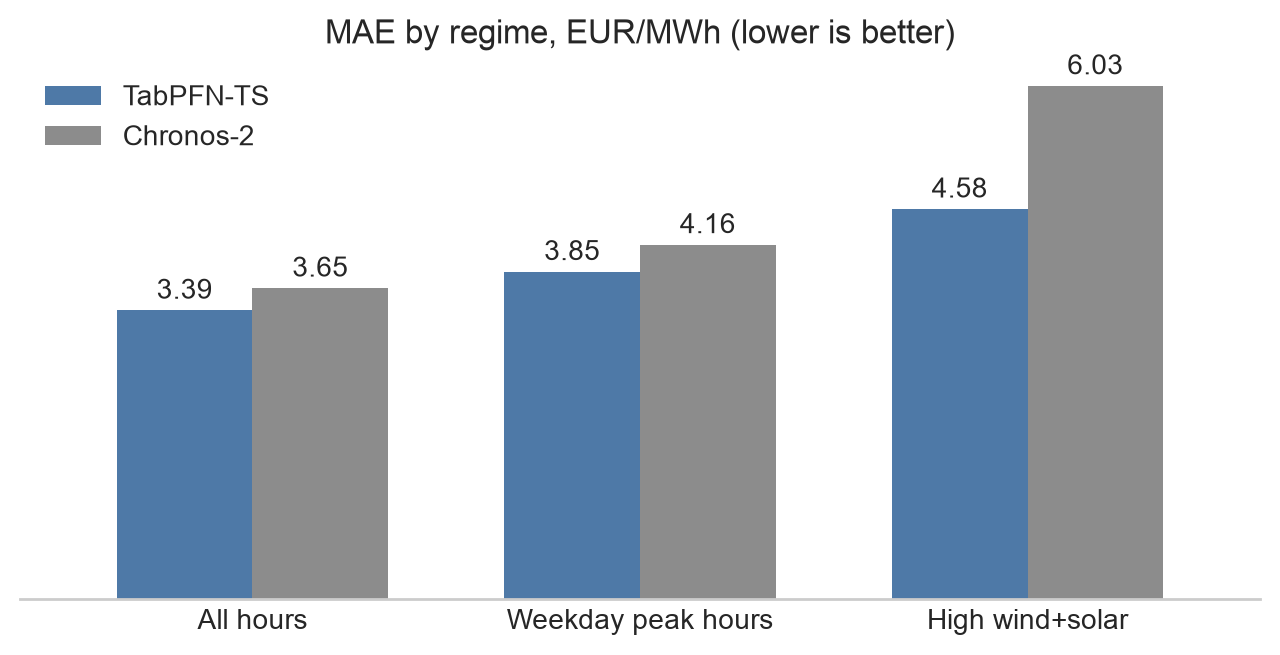

In [9]:
ax = by_regime[["TabPFN-TS MAE", "Chronos-2 MAE"]].plot.bar(figsize=(8, 3.5), color=[COLORS[model] for model in FORECASTS], rot=0, width=0.7)
for bars in ax.containers:
    ax.bar_label(bars, fmt="%.2f", padding=2)
ax.set(title="MAE by regime, EUR/MWh (lower is better)", yticks=[])
ax.legend(list(FORECASTS), frameon=False, loc="upper left")
ax.grid(False)
ax.spines[["top", "right", "left"]].set_visible(False)
plt.show()

The bands come from the same fit as the point forecast: TabPFN predicts a full distribution for every hour, so any quantile is available at no extra cost (see the [predictive distribution cookbook](https://docs.priorlabs.ai/cookbook/predictive_distribution)). Below: the week of 23–29 October, when strong wind pushed prices below zero, with the 10–90% and 30–70% quantile bands.

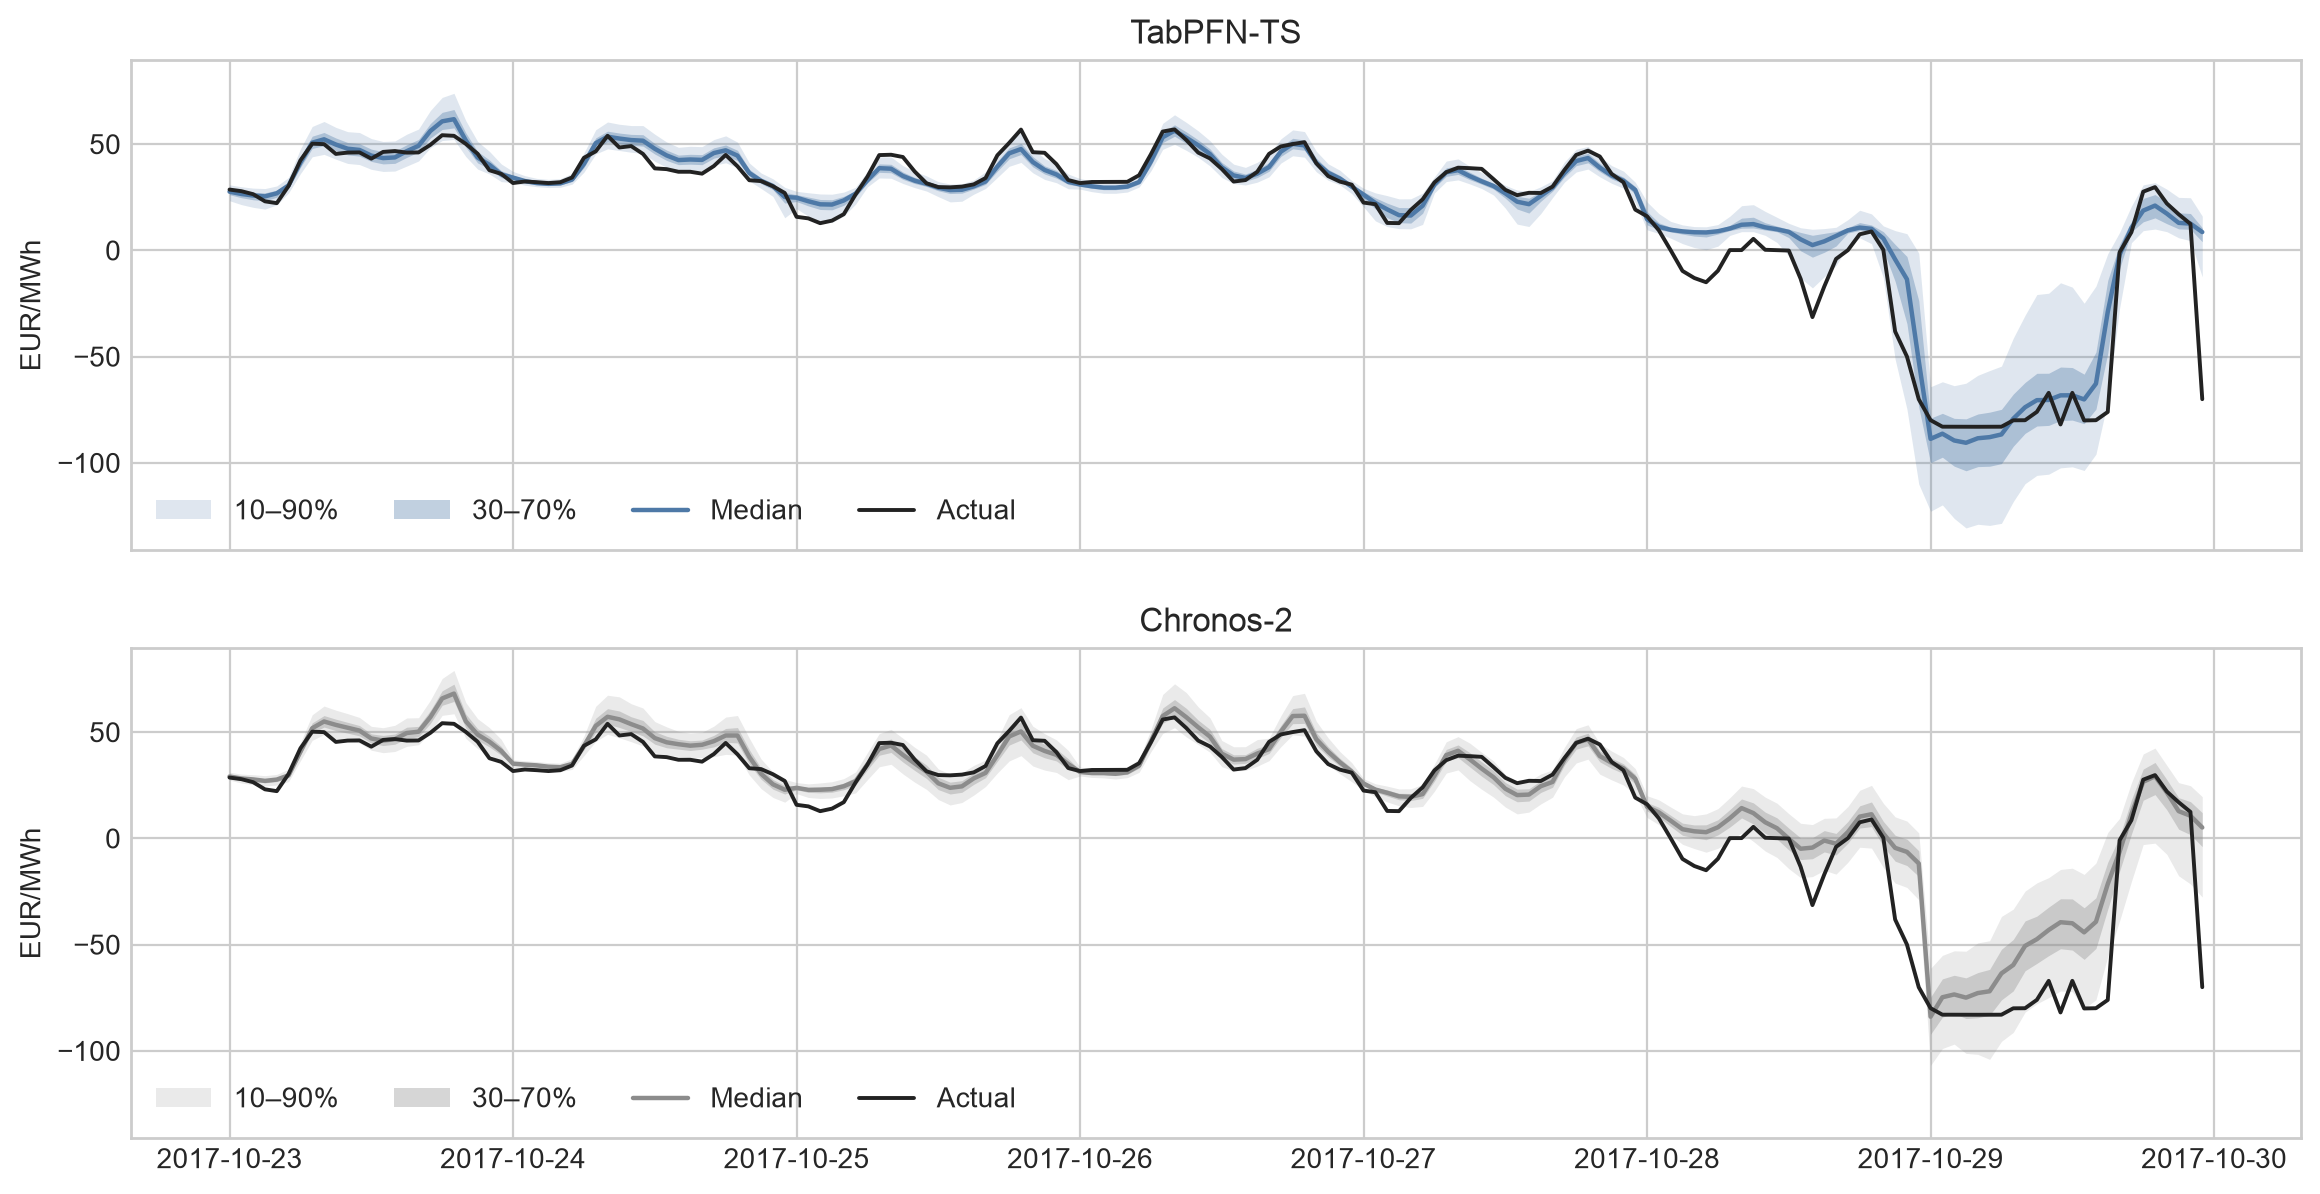

In [10]:
week = slice("2017-10-23", "2017-10-29 23:00")
fig, axes = plt.subplots(2, 1, figsize=(14, 7), sharex=True, sharey=True)
for ax, (model, q) in zip(axes, FORECASTS.items()):
    q = q.loc[week]
    ax.fill_between(q.index, q[0.1], q[0.9], color=COLORS[model], alpha=0.18, linewidth=0, label="10–90%")
    ax.fill_between(q.index, q[0.3], q[0.7], color=COLORS[model], alpha=0.35, linewidth=0, label="30–70%")
    ax.plot(q[0.5], color=COLORS[model], linewidth=1.6, label="Median")
    ax.plot(actual.loc[week], color=COLORS["Actual"], linewidth=1.4, label="Actual")
    ax.set(title=model, ylabel="EUR/MWh")
    ax.legend(loc="lower left", ncol=4)
plt.show()

## Takeaways

- **Lower error on identical inputs.** TabPFN-TS beats Chronos-2 on these weeks, most clearly when wind and solar output is high. Its 10–90% band holds the actual price 81% of the time, as promised.
- **No feature engineering, no training.** One API fit per day on the raw prices and the two published forecasts gives the full quantile forecast.
- **Backtest before you trade.** Both models saw the same history and inputs, but 12 weeks are a small sample. Check the result over at least a year on your own market.
- **Adapt it.** Replace the data file and the columns in `COVARIATES` with any drivers known a day ahead, and try a longer history with `max_context_length` (up to 32,768 hours). To see why the model forecasts what it does, see the [time series interpretability](https://docs.priorlabs.ai/cookbook/time_series_interpretability) cookbook.